# 06 · Challenger: LightGBM against the champion scorecard

## What this notebook is, and where it sits in the project

Banks rarely trust one model. Next to the **champion** (the model in use) they keep a **challenger**: a different method built on the same data, to answer "are we leaving performance on the table, and if so, why?" Notebook 05 built the champion, a six-feature WoE logistic scorecard. This notebook builds the challenger with **LightGBM**, a gradient-boosted tree model, the standard high-performance method for tabular credit data.

It answers five questions:

1. With **exactly the same six inputs**, how much better does a flexible model rank borrowers?
2. With **all 24 candidate features**, how much more?
3. **Where** does the gain come from: finer shapes within features, or interactions between them?
4. Would **more data** or **more complexity** help (learning curve and fitting graph, Provost and Fawcett, chapter 5)?
5. How do **alternative scorecards** compare, including the D-012 sensitivity run that adds Bondora's interest rate back?

## Rules this notebook follows

* **Same samples, same target** as the champion (notebook 03), and the same leakage guard.
* **Tuning uses the train sample only**, with forward-chaining validation by issue year: fit on 2016 to 2017, check on 2018; fit on 2016 to 2018, check on 2019. Time order is kept, like the real use of a model.
* **The test and out-of-time samples are used once**, for the final comparison, after every choice is made.
* **Monotone constraints** stop the challenger from learning patterns a credit officer would reject (for example, risk rising with customer tenure).

As before, every step has **Why this step**, **the code**, **What the result shows**, **Recommended action**. The notebook reads the warehouse read-only and writes `data/processed/challenger_lgbm.txt` and `data/processed/challenger_metrics.json` (git-ignored).

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Decision tree** | A model that splits loans into groups by asking yes/no questions ("tenure above 300 days?"), then predicts each group's default rate. |
| **Gradient boosting (LightGBM)** | Hundreds of small trees, each correcting the errors of the ones before. Very flexible: it can follow any shape and any interaction in the data. |
| **Number of leaves** | How many final groups one tree may have. More leaves = more complex trees. |
| **Early stopping** | Stop adding trees when the validation score stops improving, to avoid fitting noise. |
| **Monotone constraint** | Forces the prediction to only rise (or only fall) as a feature grows, for example "more tenure never means more risk". |
| **Interaction** | When the effect of one feature depends on another, for example recent borrowing matters more in Finland than in Estonia. A logistic scorecard adds effects up; it has no interactions unless they are built in. |
| **Additive model** | A model with no interactions: the score is a sum of one effect per feature. A scorecard is additive. |
| **Forward-chaining validation** | Train on earlier years, validate on the next year, so the model is always tested on loans issued after the ones it learned from. |
| **Fitting graph** | Train and validation score as model complexity grows. When the validation score stops rising while the train score keeps rising, the model has started to memorise noise. |
| **Learning curve** | Test score as the amount of training data grows. If it is still rising at 100%, more data would help. |
| **Champion / challenger** | The model in use, and the alternative it is regularly compared with. |

## Step 0. Setup

### Why this step
Load the libraries and the pipeline functions. `cvxpy` is imported first: on Windows it must load before pandas (D-026). LightGBM fits the challenger; the champion comes from `data/processed/scorecard.json` and `binning_process.pkl` (notebook 05 or `make train`).

In [1]:
import logging
logging.disable(logging.WARNING)               # hide solver-probe messages from cvxpy
import cvxpy  # noqa: F401  load before pandas on Windows (D-026)
import json
import sys
import time
import warnings
from itertools import combinations
from pathlib import Path

import duckdb
import lightgbm as lgb                         # the challenger
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from optbinning import BinningProcess, OptimalBinning

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
PROC = ROOT / "data" / "processed"
for f in ["model_samples.parquet", "binning_process.pkl", "scorecard.json"]:
    assert (PROC / f).exists(), f"{f} missing: run make train (or notebooks 03 to 05)"
try:
    from pdengine import settings as S
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine import settings as S
from pdengine.dataset import load_model_data
from pdengine.registry import check_model_columns, load_registry
from pdengine.scorecard import Scorecard, brier, gini, ks
from pdengine.selection import transform

con = duckdb.connect(str(S.DB_PATH), read_only=True)
reg = load_registry()
SEED = S.SEED

BLUE, GREY, ORANGE, GREEN = "#2a78d6", "#b5b3ad", "#d97a2b", "#3c9a5f"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("LightGBM", lgb.__version__)

LightGBM 4.5.0


### What the result shows
Libraries loaded.

### Recommended action
None.

## Step 1. Data, the champion, and the challenger's inputs

### Why this step
The challenger must see the same loans and the same allowed features as the champion. `load_model_data` builds the 24 candidate, derived and history features through the registry (exactly as `make train` does), and the champion's PDs are recomputed from its saved bins and coefficients.

LightGBM takes the **raw** feature values, not WoE: it finds its own cut points, at full resolution, and handles empty values itself. Categories (country with bureau grade, home ownership, education...) are given as categories.

**Monotone constraints.** For features where economics fixes the direction, the challenger is forced to follow it: `+1` means "a higher value never lowers the predicted PD", `-1` the opposite. They are the same directions the scorecard's bins follow. Features with no clear economic direction (or whose pooled direction is a country effect, notebook 04 step 5, such as raw income) are left free.

In [2]:
samples = pd.read_parquet(PROC / "model_samples.parquet")
data = load_model_data(con, samples, reg)
y, sample, country = data.y, data.sample, data.country
is_train, is_test, is_oot = sample.eq("train"), sample.eq("test"), sample.eq("oot")
year = data.issue_date.dt.year

# The champion, recomputed from its saved bins and coefficients.
bins = BinningProcess.load(str(PROC / "binning_process.pkl"))
champion = Scorecard.from_json(PROC / "scorecard.json")
woe = transform(bins, data.X, "woe")
pd_champion = champion.predict_pd(woe)
SIX = champion.features

# Challenger inputs: raw values, categories as pandas categories (levels taken from train).
X = data.X.copy()
for c in X.columns:
    if X[c].dtype == object:
        X[c] = pd.Categorical(X[c], categories=sorted(X.loc[is_train, c].dropna().unique()))
ALL = list(X.columns)
check_model_columns(ALL, reg)                     # the leakage guard, on the challenger's inputs too

MONOTONE = {   # +1: higher value never lowers the PD; -1: never raises it
    "days_since_first_loan": -1, "days_since_last_loan": -1, "NoOfPreviousLoansBeforeLoan": -1,
    "AmountOfPreviousLoansBeforeLoan": -1, "NewCreditCustomer": 1, "income_vs_country_median": -1,
    "AppliedAmount": 1, "Amount": 1, "ExistingLiabilities": -1, "LiabilitiesTotal": -1,
}
print(f"{len(X):,} loans; champion features: {SIX}")
print(f"Challenger candidates: {len(ALL)} features, {sum(c in MONOTONE for c in ALL)} with a monotone constraint")

155,725 loans; champion features: ['country_bureau_grade', 'days_since_first_loan', 'days_since_last_loan', 'HomeOwnershipType', 'AppliedAmount', 'income_vs_country_median']
Challenger candidates: 24 features, 10 with a monotone constraint


### What the result shows
155,725 loans, the six champion features, and 24 candidate features for the full challenger, all through the leakage guard. Ten of them have a monotone constraint.

### Recommended action
None.

## Step 2. Tune the challenger on the train sample only

### Why this step
LightGBM has settings (how big each tree may be, how many loans a leaf must hold, how many trees) that change its result. They are chosen with **forward-chaining validation inside the train sample**: train on 2016 to 2017 and validate on 2018, then train on 2016 to 2018 and validate on 2019, and average the two validation Ginis. The number of trees is set by early stopping. The test and out-of-time samples play no part.

The grid is small on purpose: tree size (7 to 63 leaves) and the minimum leaf size (200 or 1,000 loans). The same search is run for the six champion features and for all 24 candidates.

The results also give the **fitting graph**: train and validation Gini as the trees grow more complex.

In [3]:
def make_lgbm(cols, num_leaves, min_child_samples, n_estimators=2000, **extra):
    return lgb.LGBMClassifier(
        n_estimators=n_estimators, learning_rate=0.05, num_leaves=num_leaves,
        min_child_samples=min_child_samples, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        monotone_constraints=[MONOTONE.get(c, 0) for c in cols],
        monotone_constraints_method="advanced", random_state=SEED, verbose=-1, **extra)


def forward_chaining(cols, num_leaves, min_child_samples, **extra):
    """Mean train and validation Gini over the 2018 and 2019 folds, and the mean best tree count."""
    out = []
    for valid_year in [2018, 2019]:
        fit_on, check_on = is_train & (year < valid_year), is_train & (year == valid_year)
        m = make_lgbm(cols, num_leaves, min_child_samples, **extra).fit(
            X.loc[fit_on, cols], y[fit_on], eval_set=[(X.loc[check_on, cols], y[check_on])],
            eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
        out.append((gini(y[fit_on], m.predict_proba(X.loc[fit_on, cols])[:, 1]),
                    gini(y[check_on], m.predict_proba(X.loc[check_on, cols])[:, 1]), m.best_iteration_))
    tr_g, va_g, it = np.mean(out, axis=0)
    return tr_g, va_g, int(round(it))


grid = []
for inputs, cols in [("6 champion features", SIX), ("24 candidates", ALL)]:
    for nl in [7, 15, 31, 63]:
        for mcs in [200, 1000]:
            tr_g, va_g, it = forward_chaining(cols, nl, mcs)
            grid.append({"inputs": inputs, "num_leaves": nl, "min_child_samples": mcs,
                         "train_gini": tr_g, "valid_gini": va_g, "trees": it})
grid = pd.DataFrame(grid)
best = grid.loc[grid.groupby("inputs")["valid_gini"].idxmax()].set_index("inputs")
display(grid.round(4))
best.round(4)

,inputs,num_leaves,min_child_samples,train_gini,valid_gini,trees
0,6 champion features,7,200,0.5382,0.4517,103
1,6 champion features,7,1000,0.5351,0.4510,103
2,6 champion features,15,200,0.5449,0.4544,56
3,6 champion features,15,1000,0.5390,0.4526,84
4,6 champion features,31,200,0.5497,0.4542,55
5,6 champion features,31,1000,0.5399,0.4532,86
6,6 champion features,63,200,0.5507,0.4548,53
7,6 champion features,63,1000,0.5399,0.4532,86
8,24 candidates,7,200,0.5591,0.4571,102
9,24 candidates,7,1000,0.5519,0.4548,88


,num_leaves,min_child_samples,train_gini,valid_gini,trees
inputs,,,,,
24 candidates,15,200,0.5768,0.4594,74
6 champion features,63,200,0.5507,0.4548,53


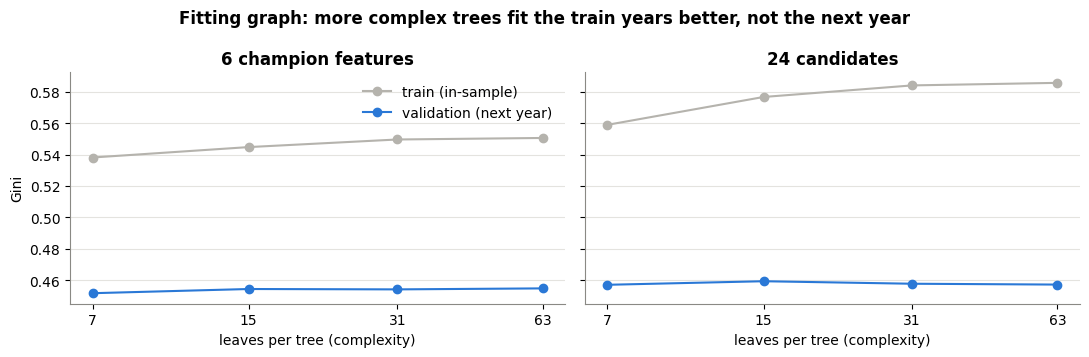

In [4]:
# Fitting graph: train vs validation Gini as the trees grow (min leaf size 200).
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, inputs in zip(axes, ["6 champion features", "24 candidates"]):
    g = grid[(grid["inputs"] == inputs) & (grid["min_child_samples"] == 200)]
    ax.plot(g["num_leaves"], g["train_gini"], color=GREY, marker="o", label="train (in-sample)")
    ax.plot(g["num_leaves"], g["valid_gini"], color=BLUE, marker="o", label="validation (next year)")
    ax.set_xscale("log", base=2); ax.set_xticks([7, 15, 31, 63], ["7", "15", "31", "63"])
    ax.set_title(inputs); ax.set_xlabel("leaves per tree (complexity)")
axes[0].set_ylabel("Gini"); axes[0].legend(frameon=False)
fig.suptitle("Fitting graph: more complex trees fit the train years better, not the next year", fontweight="bold")
plt.tight_layout(); plt.show()

### What the result shows
* **The validation Gini barely moves across the grid** (0.451 to 0.455 with six features, 0.455 to 0.459 with 24). The challenger's result does not hang on a lucky setting.
* **The fitting graph** shows the classic pattern: the train Gini keeps climbing with bigger trees (0.538 to 0.551 with six features, 0.559 to 0.586 with 24) while the validation Gini stays flat. The gap between the two lines is the part the model memorises and that does not carry to the next year. Early stopping (53 to 103 trees) keeps that gap in check.
* Chosen settings: six features, 63 leaves, min 200 loans per leaf, 53 trees; 24 features, 15 leaves, min 200 loans per leaf, 74 trees.

### Recommended action
Use the best setting of each input set for the final challengers.

## Step 3. The final comparison: test and out-of-time

### Why this step
Each challenger is refitted on the whole train sample with its chosen settings and tree count, then scored, **once**, on the test and out-of-time samples, next to the champion and Bondora's PD. A paired bootstrap of the Gini difference against the champion (same loans scored by both) shows whether a gap is larger than chance.

In [5]:
def fit_final(cols, inputs, frame=None, **extra):
    frame = X if frame is None else frame
    b = best.loc[inputs]
    m = make_lgbm(cols, int(b["num_leaves"]), int(b["min_child_samples"]), n_estimators=int(b["trees"]), **extra)
    return m.fit(frame.loc[is_train, cols], y[is_train])


lgbm6 = fit_final(SIX, "6 champion features")
lgbm24 = fit_final(ALL, "24 candidates")
pd_lgbm6 = pd.Series(lgbm6.predict_proba(X[SIX])[:, 1], index=X.index)
pd_lgbm24 = pd.Series(lgbm24.predict_proba(X[ALL])[:, 1], index=X.index)
MODELS = {"champion scorecard": pd_champion, "LightGBM, 6 features": pd_lgbm6,
          "LightGBM, 24 features": pd_lgbm24, "Bondora PD": data.bondora_pd}


def paired_diff(mask, a, b, n_boot=300):
    """Gini(a) - Gini(b) on the same resampled loans: 95% interval."""
    rng = np.random.default_rng(SEED)
    t, sa, sb = y[mask].to_numpy(), a[mask].to_numpy(), b[mask].to_numpy()
    d = [gini(t[i], sa[i]) - gini(t[i], sb[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(n_boot))]
    return np.percentile(d, [2.5, 97.5])


rows = []
for s_name, m in [("test", is_test), ("oot", is_oot)]:
    for name, p in MODELS.items():
        lo, hi = paired_diff(m, p, pd_champion) if name != "champion scorecard" else (np.nan, np.nan)
        rows.append({"sample": s_name, "model": name, "gini": gini(y[m], p[m]), "ks": ks(y[m], p[m]),
                     "brier": brier(y[m], p[m]), "mean_pd": p[m].mean(),
                     "gini_minus_champion": gini(y[m], p[m]) - gini(y[m], pd_champion[m]),
                     "diff_low": lo, "diff_high": hi})
compare = pd.DataFrame(rows)
display(compare.round(3))
# Does the full challenger also beat Bondora's own PD out of time?
for name in ["LightGBM, 6 features", "LightGBM, 24 features"]:
    lo, hi = paired_diff(is_oot, MODELS[name], data.bondora_pd)
    print(f"OOT Gini, {name} minus Bondora PD: "
          f"{gini(y[is_oot], MODELS[name][is_oot]) - gini(y[is_oot], data.bondora_pd[is_oot]):+.3f}  (95% {lo:+.3f} to {hi:+.3f})")

,sample,model,gini,ks,brier,mean_pd,gini_minus_champion,diff_low,diff_high
0,test,champion scorecard,0.459,0.354,0.185,0.315,0.000,NaN,NaN
1,test,"LightGBM, 6 features",0.486,0.372,0.182,0.316,0.027,0.023,0.031
2,test,"LightGBM, 24 features",0.502,0.377,0.179,0.315,0.043,0.039,0.047
3,test,Bondora PD,0.414,0.314,0.193,0.264,-0.045,-0.055,-0.033
4,oot,champion scorecard,0.368,0.267,0.137,0.269,0.000,NaN,NaN
5,oot,"LightGBM, 6 features",0.411,0.293,0.127,0.256,0.043,0.038,0.048
6,oot,"LightGBM, 24 features",0.419,0.292,0.128,0.255,0.051,0.045,0.056
7,oot,Bondora PD,0.405,0.300,0.116,0.174,0.037,0.019,0.055


OOT Gini, LightGBM, 6 features minus Bondora PD: +0.006  (95% -0.011 to +0.023)
OOT Gini, LightGBM, 24 features minus Bondora PD: +0.014  (95% -0.003 to +0.030)


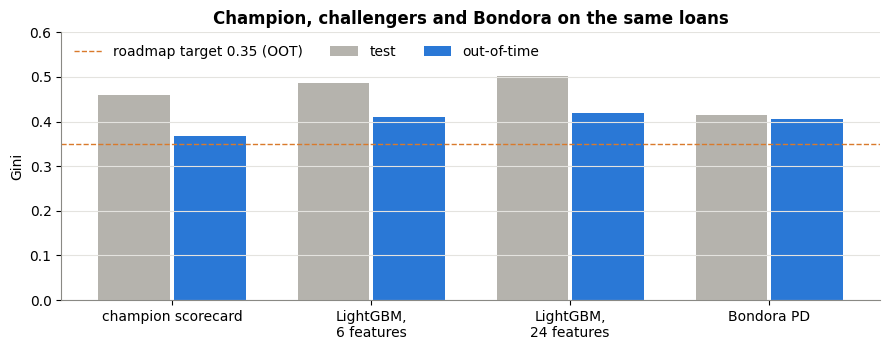

In [6]:
fig, ax = plt.subplots()
names = list(MODELS)
xs = np.arange(len(names))
for k, (s_name, colour) in enumerate([("test", GREY), ("oot", BLUE)]):
    g = compare[compare["sample"] == s_name].set_index("model").loc[names, "gini"]
    ax.bar(xs + (k - 0.5) * 0.38, g, width=0.36, color=colour, label={"test": "test", "oot": "out-of-time"}[s_name])
ax.axhline(0.35, color=ORANGE, linewidth=1, linestyle="--", label="roadmap target 0.35 (OOT)")
ax.set_xticks(xs, [n.replace(", ", ",\n") for n in names]); ax.set_ylabel("Gini"); ax.set_ylim(0, 0.6)
ax.set_title("Champion, challengers and Bondora on the same loans"); ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

### What the result shows
| | Test Gini | OOT Gini | OOT KS | OOT Brier | OOT gain vs champion (95%) |
|---|---|---|---|---|---|
| Champion scorecard | 0.459 | 0.368 | 0.267 | 0.137 | |
| LightGBM, 6 features | 0.486 | 0.411 | 0.293 | 0.127 | +0.043 (+0.038 to +0.048) |
| LightGBM, 24 features | 0.502 | 0.419 | 0.292 | 0.128 | +0.051 (+0.045 to +0.056) |
| Bondora PD | 0.414 | 0.405 | 0.300 | 0.116 | +0.037 (+0.019 to +0.055) |

* **With the same six inputs, the challenger ranks clearly better**: +0.027 Gini on test and +0.043 out of time, far outside the bootstrap noise. The champion's limits are its form, not its data.
* **All 24 candidates add a little more** (+0.016 test, +0.008 OOT over six features). The six chosen features already carry most of the information.
* **The challenger keeps more of its power out of time** than the champion (it loses 0.08 Gini versus 0.09), and it reaches Bondora's level out of time without using Bondora's interest rate. It is **not significantly above** Bondora: +0.006 (95% −0.011 to +0.023) with six features and +0.014 (−0.003 to +0.030) with 24. The honest claim is *"matches Bondora's model"*.
* Brier scores are better for LightGBM, but every model's Brier out of time is dominated by the level drift (step 7).

### Recommended action
Keep both models and decide on the trade-off in step 9. A gain of 0.04 to 0.05 OOT Gini is large in credit terms, so the question is not *whether* the challenger is better but *whether the gain is worth losing a points table*.

## Step 4. Where does the gain come from?

### Why this step
A flexible model can beat a scorecard in two ways: **finer shapes** inside each feature (the scorecard has 4 to 8 bins per feature; trees can use many more cut points), or **interactions** between features (the scorecard adds effects up; trees can let one feature change the effect of another). The answer decides how the champion could be improved.

We refit the six-feature challenger with the same settings under three rules:

1. **Additive:** no interactions allowed, only finer shapes. This is a scorecard with unlimited bins.
2. **Interactions with country only:** each feature may interact with `country_bureau_grade`, nothing else.
3. **Free interactions:** the full challenger from step 3.

Then, to see which interactions matter most, each of the 15 pairs of features is allowed on its own and its gain over the additive model measured **on the test sample**.

In [7]:
b6 = best.loc["6 champion features"]
cb = SIX.index("country_bureau_grade")
RULES = {
    "additive (no interactions)": [[i] for i in range(len(SIX))],
    "interactions with country only": [[cb, i] for i in range(len(SIX)) if i != cb],
    "free interactions": None,
}
decomp, pds = [], {}
for rule, inter in RULES.items():
    extra = {"interaction_constraints": inter} if inter else {}
    m = make_lgbm(SIX, int(b6["num_leaves"]), int(b6["min_child_samples"]), n_estimators=int(b6["trees"]), **extra)
    p = pd.Series(m.fit(X.loc[is_train, SIX], y[is_train]).predict_proba(X[SIX])[:, 1], index=X.index)
    pds[rule] = p
    r = {"model": rule, "test": gini(y[is_test], p[is_test]), "oot": gini(y[is_oot], p[is_oot])}
    r.update({f"oot_{c}": gini(y[is_oot & country.eq(c)], p[is_oot & country.eq(c)]) for c in ["EE", "FI", "ES"]})
    decomp.append(r)
for name, p in [("champion scorecard", pd_champion), ("Bondora PD", data.bondora_pd)]:
    r = {"model": name, "test": gini(y[is_test], p[is_test]), "oot": gini(y[is_oot], p[is_oot])}
    r.update({f"oot_{c}": gini(y[is_oot & country.eq(c)], p[is_oot & country.eq(c)]) for c in ["EE", "FI", "ES"]})
    decomp.append(r)
pd.DataFrame(decomp).set_index("model").round(3)

,test,oot,oot_EE,oot_FI,oot_ES
model,,,,,
additive (no interactions),0.458,0.363,0.313,0.112,0.124
interactions with country only,0.473,0.380,0.330,0.213,0.153
free interactions,0.486,0.411,0.339,0.313,0.167
champion scorecard,0.459,0.368,0.323,0.154,0.117
Bondora PD,0.414,0.405,0.359,0.284,0.162


In [8]:
# Which single pair of features adds most, on the TEST sample? (out-of-time shown for information)
additive = pds["additive (no interactions)"]
base_test = gini(y[is_test], additive[is_test])
pairs = []
for i, j in combinations(range(len(SIX)), 2):
    inter = [[i, j]] + [[k] for k in range(len(SIX)) if k not in (i, j)]
    m = make_lgbm(SIX, int(b6["num_leaves"]), int(b6["min_child_samples"]), n_estimators=int(b6["trees"]),
                  interaction_constraints=inter).fit(X.loc[is_train, SIX], y[is_train])
    p = pd.Series(m.predict_proba(X[SIX])[:, 1], index=X.index)
    pairs.append({"pair": f"{SIX[i]} x {SIX[j]}", "test_gain": gini(y[is_test], p[is_test]) - base_test,
                  "test_gain_finland": gini(y[is_test & country.eq("FI")], p[is_test & country.eq("FI")])
                                       - gini(y[is_test & country.eq("FI")], additive[is_test & country.eq("FI")])})
pd.DataFrame(pairs).sort_values("test_gain", ascending=False).round(4).head(8)

,pair,test_gain,test_gain_finland
3,country_bureau_grade x AppliedAmount,0.0072,0.0296
1,country_bureau_grade x days_since_last_loan,0.0062,0.0257
0,country_bureau_grade x days_since_first_loan,0.0061,0.0261
7,days_since_first_loan x AppliedAmount,0.0051,0.0178
12,HomeOwnershipType x AppliedAmount,0.0049,0.0145
2,country_bureau_grade x HomeOwnershipType,0.0047,0.0098
5,days_since_first_loan x days_since_last_loan,0.0043,0.0097
6,days_since_first_loan x HomeOwnershipType,0.0031,0.0059


### What the result shows
* **Finer shapes alone add nothing.** The additive challenger (0.458 / 0.363) matches the scorecard (0.459 / 0.368). Our bins already capture each feature's shape; unlimited bins do not help.
* **The whole gain is interactions.** Allowing interactions with country only gives +0.015 test and +0.017 OOT; free interactions give the rest (+0.028 test, +0.048 OOT over additive).
* **Finland is where it matters.** Out of time the scorecard reaches only 0.154 Gini in Finland; the additive tree 0.112; free interactions 0.313, level with Bondora's 0.284. In Estonia the gain is small (0.323 to 0.339).
* **The top pairs all involve country** (country × AppliedAmount, × days_since_last_loan, × days_since_first_loan), and their gain in Finland is four times the overall gain. In plain words: *loan size and borrowing history mean something different in Finland*, and one pooled points table cannot express that.

### Recommended action
This points to a concrete improvement for the champion that keeps it a scorecard: **segment it by country** (a separate scorecard for Finland, or for Finland and Spain), the textbook answer when interactions concentrate in one segment (Siddiqi, chapter 6). Finland has about 25,000 train loans, enough for its own card. This is logged as a Phase 4 candidate (D-027), not done here: it is a new champion, and it would need its own selection and its own test.

## Step 5. Learning curve: would more data help?

### Why this step
If a model's test score is still rising when it uses all the training data, more data would help; if it has flattened, the limit is the information in the features (Provost and Fawcett, chapter 5). We refit the champion (its coefficients, on the fixed bins) and the six-feature challenger (same settings) on 10%, 25%, 50% and 100% of the train sample, drawn at random, and score the test sample each time.

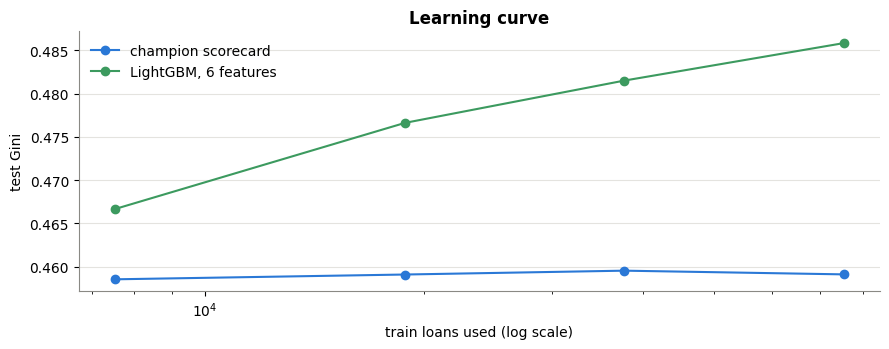

,train_share,train_loans,scorecard_test_gini,lightgbm6_test_gini
0,0.10,7530,0.4585,0.4667
1,0.25,18825,0.4591,0.4766
2,0.50,37651,0.4595,0.4815
3,1.00,75302,0.4591,0.4858


In [9]:
rng = np.random.default_rng(SEED)
train_idx = X.index[is_train].to_numpy()
order = rng.permutation(len(train_idx))
curve = []
for share in [0.10, 0.25, 0.50, 1.00]:
    part = pd.Index(train_idx[order[: int(share * len(train_idx))]])
    logit = sm.Logit(y[part], sm.add_constant(woe.loc[part, SIX])).fit(disp=0)
    p_sc = logit.predict(sm.add_constant(woe[SIX]))
    m = make_lgbm(SIX, int(b6["num_leaves"]), int(b6["min_child_samples"]), n_estimators=int(b6["trees"])).fit(
        X.loc[part, SIX], y[part])
    p_gb = pd.Series(m.predict_proba(X[SIX])[:, 1], index=X.index)
    curve.append({"train_share": share, "train_loans": len(part),
                  "scorecard_test_gini": gini(y[is_test], p_sc[is_test]),
                  "lightgbm6_test_gini": gini(y[is_test], p_gb[is_test])})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots()
ax.plot(curve["train_loans"], curve["scorecard_test_gini"], color=BLUE, marker="o", label="champion scorecard")
ax.plot(curve["train_loans"], curve["lightgbm6_test_gini"], color=GREEN, marker="o", label="LightGBM, 6 features")
ax.set_xscale("log"); ax.set_xlabel("train loans used (log scale)"); ax.set_ylabel("test Gini")
ax.set_title("Learning curve"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
curve.round(4)

### What the result shows
* **The scorecard is flat**: 0.459 with 10% of the train loans and 0.459 with 100%. With six features and a few bins each, it has learned all it can from 7,500 loans. (Its bins were fitted on the full train sample, so the curve shows the coefficients only; the bins would not change much either.)
* **The challenger is still climbing** (0.467 to 0.486), more slowly at the end. Interactions need many loans per country and segment to show, so more data keeps helping a flexible model.

### Recommended action
More data will not improve the champion; a richer form (segments, step 4) can. For the challenger, refitting on more years when they mature is worth it.

## Step 6. Alternative scorecards and the D-012 sensitivity run

### Why this step
Siddiqi (chapter 10) recommends comparing several candidate scorecards, not following one path. Two alternatives matter here:

* **Champion plus `Education`.** Education sits right on the IV cut-off (0.019, D-023); does forcing it in help?
* **Champion plus Bondora's price (`Interest`, `MonthlyPayment`).** D-012 kept them out because Bondora sets the rate from its own risk rating, so they carry Bondora's view of the borrower. The sensitivity run shows how much that view is worth. The same is done for the 24-feature challenger.

`Interest` and `MonthlyPayment` are application columns that the registry deliberately does not allow (D-012), so this step reads them separately and **never saves** a model that uses them. This is the one place the leakage guard is bypassed, on purpose and for analysis only.

In [10]:
con.register("sample_keys", samples[["loan_key"]])
price = (con.execute('SELECT loan_key, "Interest", "MonthlyPayment" FROM loans JOIN sample_keys USING (loan_key)')
            .df().set_index("loan_key").loc[X.index])
woe_alt = woe[SIX].copy()
woe_alt["Education"] = transform(bins, data.X, "woe")["Education"]
for c in ["Interest", "MonthlyPayment"]:          # bins fitted on train only, as for every feature
    ob = OptimalBinning(c, dtype="numerical", min_bin_size=S.MIN_BIN_SIZE, monotonic_trend="auto_asc_desc")
    woe_alt[c] = ob.fit(price.loc[is_train, c].values, y[is_train].values).transform(price[c].values, metric="woe")


def scorecard_variant(cols):
    m = sm.Logit(y[is_train], sm.add_constant(woe_alt.loc[is_train, cols])).fit(disp=0)
    return m.predict(sm.add_constant(woe_alt[cols])), bool((m.params.drop("const") < 0).all())


variants = {}
for name, cols in [("champion (6 features)", SIX), ("champion + Education", SIX + ["Education"]),
                   ("champion + Interest (D-012)", SIX + ["Interest"]),
                   ("champion + Interest + MonthlyPayment (D-012)", SIX + ["Interest", "MonthlyPayment"])]:
    variants[name] = scorecard_variant(cols)
X_price = X.join(price)
gb_price = fit_final(ALL + ["Interest", "MonthlyPayment"], "24 candidates", frame=X_price)
variants["LightGBM, 24 features + price (D-012)"] = (
    pd.Series(gb_price.predict_proba(X_price[ALL + ["Interest", "MonthlyPayment"]])[:, 1], index=X.index), None)
variants["Interest rate alone"] = (price["Interest"], None)
variants["Bondora PD"] = (data.bondora_pd, None)
pd.DataFrame({name: {"test": gini(y[is_test], p[is_test]), "oot": gini(y[is_oot], p[is_oot]), "all_signs_negative": s}
              for name, (p, s) in variants.items()}).T.round(3)

,test,oot,all_signs_negative
champion (6 features),0.459092,0.368148,True
champion + Education,0.462035,0.367532,True
champion + Interest (D-012),0.480833,0.476488,True
champion + Interest + MonthlyPayment (D-012),0.480977,0.475094,False
"LightGBM, 24 features + price (D-012)",0.522715,0.503628,NaN
Interest rate alone,0.437364,0.39624,NaN
Bondora PD,0.414352,0.405088,NaN


### What the result shows
| Model | Test Gini | OOT Gini |
|---|---|---|
| Champion | 0.459 | 0.368 |
| + Education | 0.462 | 0.368 |
| + Interest (D-012) | 0.481 | 0.476 |
| + Interest + MonthlyPayment (D-012) | 0.481 | 0.475 (a coefficient flips sign) |
| LightGBM 24 + price (D-012) | 0.523 | 0.504 |
| Interest rate alone | 0.437 | 0.396 |
| Bondora PD | 0.414 | 0.405 |

* **Education does not help** out of time (0.368 either way), which supports leaving it out (D-023).
* **Bondora's interest rate alone ranks almost as well as Bondora's PD.** That confirms D-012: the rate *is* Bondora's risk view, priced.
* **Adding it to the champion lifts OOT Gini by 0.11**, and the challenger by 0.08. Our models and Bondora's know different things: combined, they rank better than either. MonthlyPayment adds nothing once Interest is in (it is mostly Interest × Amount) and flips a sign.

### Recommended action
Keep D-012: the project's purpose is an **independent** model to benchmark Bondora against, and a model that copies Bondora's price cannot do that. The sensitivity result is still worth stating in interviews: *a lender that already has an internal rating should feed it into its scorecard; it is the single strongest feature.* Nothing from this step is saved.

## Step 7. Calibration of the challenger

### Why this step
Like the champion, the challenger learned the default level of 2016 to 2019. Its ranking may be better, but its PDs face the same drift. We compare mean predicted PD with the observed rate, per sample, and per score decile out of time.

brier        mean_pd       
sample                   oot   test     oot   test
model                                             
Bondora PD             0.116  0.193   0.174  0.264
LightGBM, 24 features  0.128  0.179   0.255  0.315
LightGBM, 6 features   0.127  0.182   0.256  0.316
champion scorecard     0.137  0.185   0.269  0.315

Observed default rate: test 0.314  out-of-time 0.144


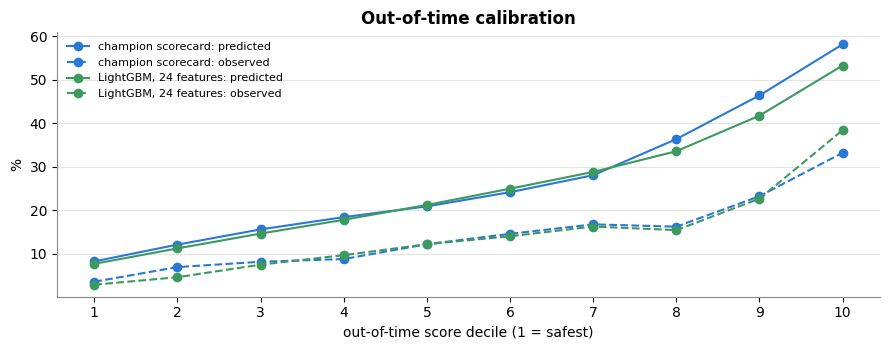

In [11]:
display(compare.pivot_table(index="model", columns="sample", values=["mean_pd", "brier"]).round(3))
print("Observed default rate: test", round(y[is_test].mean(), 3), " out-of-time", round(y[is_oot].mean(), 3))
fig, ax = plt.subplots()
for name, p, colour in [("champion scorecard", pd_champion, BLUE), ("LightGBM, 24 features", pd_lgbm24, GREEN)]:
    d = pd.DataFrame({"pd": p[is_oot], "y": y[is_oot]})
    d["decile"] = pd.qcut(d["pd"].rank(method="first"), 10, labels=False) + 1
    g = d.groupby("decile").agg(predicted=("pd", "mean"), observed=("y", "mean")) * 100
    ax.plot(g.index, g["predicted"], color=colour, marker="o", label=f"{name}: predicted")
    ax.plot(g.index, g["observed"], color=colour, marker="o", linestyle="--", label=f"{name}: observed")
ax.set_xlabel("out-of-time score decile (1 = safest)"); ax.set_ylabel("%"); ax.set_xticks(range(1, 11))
ax.set_title("Out-of-time calibration"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### What the result shows
* **All three of our models predict about 0.26 out of time against an observed 0.144**: they all learned 2016 to 2019 default levels. Bondora's PD (0.174) is closer in level but, as in notebook 05, ranks worse than our challenger.
* Within each decile the challenger's line follows the observed line in shape; the gap is a level shift, the same one the champion has.

### Recommended action
Both models need the Phase 4 recalibration before their PDs are used. Recalibration changes levels, not ranking, so it does not change the Gini comparison above.

## Step 8. Save the challenger

### Why this step
The challenger is kept for monitoring and for Phase 4 (SHAP explanations, comparison after recalibration). LightGBM saves its trees as a text file; the metrics go to a JSON file. The D-012 price model is not saved.

In [12]:
lgbm24.booster_.save_model(str(PROC / "challenger_lgbm.txt"))
(PROC / "challenger_metrics.json").write_text(json.dumps({
    "model": "LightGBM challenger, 24 candidate features, monotone constraints (notebook 06)",
    "features": ALL, "monotone": {c: MONOTONE[c] for c in ALL if c in MONOTONE},
    "settings": {k: int(v) for k, v in best.loc["24 candidates", ["num_leaves", "min_child_samples", "trees"]].items()},
    "metrics": compare.round(4).to_dict(orient="records"),
}, indent=2), encoding="utf-8")
again = lgb.Booster(model_file=str(PROC / "challenger_lgbm.txt"))
assert np.allclose(again.predict(X[ALL]), pd_lgbm24.to_numpy())
print("Saved challenger_lgbm.txt and challenger_metrics.json; reloaded model gives identical PDs")

Saved challenger_lgbm.txt and challenger_metrics.json; reloaded model gives identical PDs


### What the result shows
The saved model reproduces the challenger's PDs exactly.

### Recommended action
None.

## Step 9. Summary of findings and recommended actions

| Question | Finding | Recommended action |
|---|---|---|
| Same six inputs, flexible model? | LightGBM +0.027 test, +0.043 OOT Gini; both far outside noise | The champion's limit is its additive form |
| All 24 candidates? | +0.008 OOT more; the six features hold most of the information | Feature selection was sound |
| Where does the gain come from? | Interactions, not finer shapes; above all country × history and loan size, mostly in Finland (OOT FI Gini 0.15 → 0.31) | Phase 4 candidate: country-segmented scorecard (D-027) |
| More data? | Scorecard flat from 10% of train; LightGBM still rising | Improve the champion's form, not its sample |
| Fitting graph | Train Gini rises with tree size, validation flat; early stopping controls it | Settings chosen on train-only forward chaining |
| Alternative scorecards | Education adds nothing; Bondora's rate adds +0.11 OOT | Keep D-012 and D-023 |
| Calibration | Every model over-predicts OOT by ~12 points | Phase 4 recalibration, for both models |

### Champion or challenger?

**Keep the scorecard as champion; keep LightGBM as the challenger.** A scorecard has a points table a credit officer can read, a reason for every decline, and a form a regulator accepts without extra tooling. LightGBM's advantage is real (+0.04 to +0.05 OOT Gini) but step 4 shows it comes from one identifiable source, country interactions, which a segmented scorecard can capture. The plan is therefore:

1. Phase 4: build a country-segmented scorecard and measure how much of the gap it closes.
2. Use the challenger as a benchmark in monitoring: if its lead over the champion grows, the champion has stopped capturing the data.
3. Explain the challenger with SHAP values (Phase 4) so its decisions can be checked against the scorecard's.

### The challenger in one paragraph (for my video)

"Next to my scorecard I built a challenger with LightGBM on the same samples, tuned only on earlier years and tested once. With the same six features it ranks clearly better out of time, 0.41 Gini against 0.37, and with all candidates it matches Bondora's own model without using Bondora's interest rate. Then I asked *why*. When I forbid the trees from combining features, the advantage disappears; when I allow combinations only with country, a third of it comes back; and the biggest gain is in Finland, where my scorecard is weakest. So the lesson is not 'use a black box', it is 'one points table for three countries is too simple'. My next step is a country-segmented scorecard, which keeps the explainability and should close most of the gap."


In [13]:
con.close()   # release the warehouse file